# Modelo 1 · Sismos de Los Santos · Registro del entrenamiento

**UTSmart IA Challenge 2027 – Categoría Básica** · Riesgo sísmico por zona en Los Santos, Santander

Este cuaderno deja constancia de todo lo que se hace con los datos antes y durante el entrenamiento:
cómo llegan los datos originales, cada paso de la limpieza con el número de filas que quedan, cómo es el
conjunto de datos limpio, si los datos están normalizados, y los resultados de los modelos.

Es uno de los tres modelos del proyecto (los otros dos, sismos de todo Santander y viviendas afectadas, tienen su propia carpeta y su propio cuaderno).
Usa las mismas funciones que los scripts de `src/` y de `comun/src/`, de modo que lo que aquí se imprime es lo que de verdad
se ejecuta al entrenar. No modifica los modelos ya guardados: al final comprueba que sus resultados coinciden
con ellos.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")
MODELO = Path.cwd().parent                      # entrenamiento/1_sismos_los_santos
sys.path.insert(0, str(MODELO / "src"))
sys.path.insert(0, str(MODELO.parent / "comun" / "src"))   # código compartido: catálogo, simulador, población

import catalogo
import entrenar_modelo_sismico_los_santos as clasificador
import entrenar_modelo_sacudida as sacudida
import preparar_poblacion as poblacion

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", lambda v: f"{v:,.3f}")
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#c3c2b7"
COLOR_NIVEL = {"Bajo": "#1baf1b", "Medio": "#f5b21a", "Alto": "#d83a3a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True, "font.size": 10})
relativa = lambda ruta: Path(ruta).relative_to(catalogo.BASE_DIR).as_posix()
print("Python", sys.version.split()[0], "· pandas", pd.__version__, "· scikit-learn", clasificador.sklearn.__version__)

Python 3.11.9 · pandas 3.0.6 · scikit-learn 1.9.1


## 1. Fuentes de datos

| Fuente | Archivo original (`data/raw`) | Uso |
| :--- | :--- | :--- |
| Servicio Geológico Colombiano, catálogo de sismicidad. Filtros: departamento Santander, todos los municipios, del 01/01/2006 a la fecha de descarga (13/10/2026), formato CSV | `Santander - 01-01-2006 - 13-10-2026.csv` | Único conjunto con el que se entrena el clasificador |
| El mismo catálogo, filtrado por el municipio de Los Santos (descarga del 12/10/2026, GeoJSON) | `Los_santos - 01-01-2006 - 12-10-2026.geojson` | Ubicación y recurrencia del nido para el simulador. Fue el catálogo del primer modelo |
| USGS, *Did You Feel It?* | `intensidades_dyfi_usgs.csv` | Validar y calibrar el simulador de sacudida |
| DANE, proyecciones de población municipal 2018-2042 | `poblacion_dane/PPED-AreaMun-2018-2042_VP.xlsx` | Contar personas expuestas (no es variable de ningún modelo) |
| DANE, límites municipales (vía geoBoundaries) | `limites_municipios_santander.geojson` | Dibujar el mapa |

Los archivos originales, comunes a todos los modelos, están en `entrenamiento/data/raw` y no se modifican nunca: la limpieza se hace en memoria y el resultado se guarda aparte.

In [2]:
print("ARCHIVOS ORIGINALES (data/raw)")
for ruta in sorted(catalogo.RAW_DIR.rglob("*")):
    if ruta.is_file():
        print(f"   {relativa(ruta):75s} {ruta.stat().st_size / 1e6:8.2f} MB")

ARCHIVOS ORIGINALES (data/raw)
   data/raw/danos_y_costos/dane_divipola/divipola_municipios.csv                   0.07 MB
   data/raw/danos_y_costos/dane_viviendas_y_hogares/proyecciones_hogares_dptal_mpal_2018_2042.xlsx     0.67 MB
   data/raw/danos_y_costos/dane_viviendas_y_hogares/proyecciones_viviendas_dptal_mpal_2018_2042.xlsx     1.28 MB
   data/raw/danos_y_costos/gobernacion_santander/reporte_eventos_desastres_santander.csv     0.74 MB
   data/raw/danos_y_costos/ungrd_emergencias/emergencias_ungrd_2019.csv            1.02 MB
   data/raw/danos_y_costos/ungrd_emergencias/emergencias_ungrd_2020.csv            3.30 MB
   data/raw/danos_y_costos/ungrd_emergencias/emergencias_ungrd_2023_2024.csv      15.77 MB
   data/raw/danos_y_costos/ungrd_emergencias/emergencias_ungrd_2025.csv           11.56 MB
   data/raw/danos_y_costos/usgs_catalogo_colombia/sismos_usgs_colombia_2019_2025.geojson     0.93 MB
   data/raw/intensidades_dyfi_usgs.csv                                             0.06 

## 2. El catálogo original, tal como llega

Se lee el archivo del SGC sin tocar nada, para ver qué trae. Es el catálogo de **todo Santander**: la zona que se predice sigue siendo Los Santos,
pero el nido sísmico se extiende a los municipios vecinos y el SGC asigna parte de sus sismos a ellos (sección 5).

In [3]:
crudo = catalogo.leer_catalogo_crudo()
print(f"Filas: {len(crudo):,}   Columnas: {crudo.shape[1]}")
display(crudo.head(5))

Filas: 184,723   Columnas: 18


,id,status,rms,agency,gap,place,local_time,utc_time,magnitude,magnitude_error,nst,mag_type,latitude,latitude_error,longitude,longitude_error,depth,depth_error
0,SGC2026twxszp,manual,0.5,SGC,190,"Los Santos - Santander, Colombia",2026-10-09T09:25:19+00:00,2026-10-09T14:25:19+00:00,1.3,0.2,5,MLr_3,6.7948,3.4,-73.1283,3.4,149,4
1,SGC2026twwvog,manual,0.2,SGC,133,"Los Santos - Santander, Colombia",2026-10-09T08:58:08+00:00,2026-10-09T13:58:08+00:00,1.4,0.1,6,MLr_3,6.7898,1.1,-73.1745,1.1,157,2
2,SGC2026twwrwx,manual,0.4,SGC,134,"Los Santos - Santander, Colombia",2026-10-09T08:53:52+00:00,2026-10-09T13:53:52+00:00,1.5,0.2,7,MLr_3,6.7726,2.0,-73.1775,2.0,159,3
3,SGC2026twvfid,manual,0.7,SGC,139,"Los Santos - Santander, Colombia",2026-10-09T08:09:07+00:00,2026-10-09T13:09:07+00:00,1.7,0.2,14,MLr_3,6.7733,4.5,-73.1369,7.5,139,8
4,SGC2026twudgd,manual,0.9,SGC,65,"Los Santos - Santander, Colombia",2026-10-09T07:36:31+00:00,2026-10-09T12:36:31+00:00,2.3,0.2,36,MLr_3,6.7617,2.9,-73.1444,3.4,142,5


In [4]:
# Tipo con que llega cada columna, cuántos valores vacíos tiene y un ejemplo
vacios = crudo.apply(lambda col: (col.isna() | (col.astype(str).str.strip() == "")).sum())
resumen_crudo = pd.DataFrame({
    "tipo_original": crudo.dtypes.astype(str),
    "vacios": vacios,
    "porcentaje_vacio": (100 * vacios / len(crudo)).round(2),
    "valores_distintos": crudo.nunique(),
    "ejemplo": crudo.iloc[0].astype(str),
})
display(resumen_crudo)
print("Identificadores repetidos:", int(crudo["id"].duplicated().sum()))
print("Agencias:", crudo["agency"].value_counts().to_dict())
print("Estado de la solución:", crudo["status"].value_counts().to_dict())

,tipo_original,vacios,porcentaje_vacio,valores_distintos,ejemplo
id,str,0,0.000,184723,SGC2026twxszp
status,str,0,0.000,2,manual
rms,str,0,0.000,29,0.5
agency,str,0,0.000,1,SGC
gap,str,1,0.000,326,190
place,str,0,0.000,111,"Los Santos - Santander, Colombia"
local_time,str,0,0.000,184688,2026-10-09T09:25:19+00:00
utc_time,str,0,0.000,184688,2026-10-09T14:25:19+00:00
magnitude,str,0,0.000,64,1.3
magnitude_error,str,79091,42.820,30,0.2


Identificadores repetidos: 0
Agencias: {'SGC': 184723}
Estado de la solución: {'manual': 184720, 'automatic': 3}


**Qué se observa.** El archivo es un CSV: todo se lee como **texto**, incluidas la magnitud, la profundidad y las coordenadas,
y los datos faltantes son **cadenas vacías**. Hay que convertir cada columna a su tipo antes de poder calcular nada.

## 3. Limpieza, paso a paso

Cada paso imprime cuántas filas quedan. Son los mismos pasos de `catalogo.cargar_catalogo`.

In [5]:
pasos = [("0. Catálogo original", len(crudo))]
cat = crudo.copy()

# Paso 1: texto -> número. Lo que no es un número (cadenas vacías) queda como NaN, no como cero
for columna in catalogo.COLUMNAS_NUMERICAS:
    cat[columna] = pd.to_numeric(cat[columna], errors="coerce")
pasos.append(("1. Columnas numéricas convertidas de texto a número", len(cat)))

# Paso 2: fecha en texto -> fecha con zona horaria UTC
cat["utc_time"] = pd.to_datetime(cat["utc_time"], errors="coerce", utc=True)
pasos.append(("2. Fecha convertida a fecha UTC", len(cat)))

# Paso 3: se descartan solo las filas sin magnitud, profundidad, ubicación o fecha
sin_esenciales = int(cat[catalogo.COLUMNAS_ESENCIALES].isna().any(axis=1).sum())
cat = cat.dropna(subset=catalogo.COLUMNAS_ESENCIALES)
pasos.append((f"3. Sin filas a las que falte un dato esencial (se quitan {sin_esenciales})", len(cat)))

# Paso 4: sismos repetidos (mismo identificador)
repetidos = int(cat["id"].duplicated().sum())
cat = cat.drop_duplicates(subset="id")
pasos.append((f"4. Sin sismos repetidos (se quitan {repetidos})", len(cat)))

# Paso 5: variable derivada. Energía sísmica (Gutenberg-Richter): log10(E) = 4.8 + 1.5 M
cat["energy_joules"] = 10 ** (4.8 + 1.5 * cat["magnitude"])
cat = cat.sort_values("utc_time").reset_index(drop=True)
pasos.append(("5. Energía liberada añadida y catálogo ordenado por fecha", len(cat)))

display(pd.DataFrame(pasos, columns=["Paso", "Filas"]))

# Debe coincidir exactamente con lo que hace el script
pd.testing.assert_frame_equal(cat, catalogo.cargar_catalogo())
print("Comprobado: el resultado es idéntico al de catalogo.cargar_catalogo()")

,Paso,Filas
0,0. Catálogo original,184723
1,1. Columnas numéricas convertidas de texto a n...,184723
2,2. Fecha convertida a fecha UTC,184723
3,3. Sin filas a las que falte un dato esencial ...,184723
4,4. Sin sismos repetidos (se quitan 0),184723
5,5. Energía liberada añadida y catálogo ordenad...,184723


Comprobado: el resultado es idéntico al de catalogo.cargar_catalogo()


In [6]:
# Faltantes que quedan tras la limpieza: se conservan como NaN, no se inventan valores
faltantes = cat.isna().sum()
display(pd.DataFrame({"tipo_limpio": cat.dtypes.astype(str), "faltantes": faltantes,
                      "porcentaje": (100 * faltantes / len(cat)).round(2)}))

,tipo_limpio,faltantes,porcentaje
id,str,0,0.000
status,str,0,0.000
rms,float64,0,0.000
agency,str,0,0.000
gap,float64,1,0.000
place,str,0,0.000
local_time,str,0,0.000
utc_time,"datetime64[us, UTC]",0,0.000
magnitude,float64,0,0.000
magnitude_error,float64,79091,42.820


**Decisiones de limpieza.**

- Los faltantes **no se rellenan con ceros ni con promedios**: una magnitud o una profundidad inventada falsearía el conteo de sismos.
  Solo se descarta una fila cuando le falta un dato esencial.
- Las columnas de error y de calidad (`rms`, `gap`, `nst`, errores de localización) se conservan con sus faltantes; el modelo no las usa.
- No se eliminan valores extremos: los sismos grandes son reales y son justo los que interesan.

### Columnas que se usan y columnas que se descartan

El catálogo limpio conserva todas las columnas del original, para poder compararlo fila a fila. Pero **no todas entran al entrenamiento**:
el modelo solo usa las que describen el sismo (cuándo, dónde, a qué profundidad y con qué magnitud). La tabla siguiente lo deja explícito.

In [7]:
USO_DE_CADA_COLUMNA = {
    "magnitude":       ("Sí", "Filtro de magnitud 2,5 o mayor; magnitud media y máxima; sismos fuertes y moderados"),
    "depth":           ("Sí", "Profundidad media y su dispersión en cada celda"),
    "latitude":        ("Sí", "Asignar cada sismo a su celda"),
    "longitude":       ("Sí", "Asignar cada sismo a su celda"),
    "utc_time":        ("Sí", "Asignar cada sismo a su trimestre"),
    "energy_joules":   ("Sí", "Derivada de la magnitud: energía liberada en el último año"),
    "id":              ("Solo en la limpieza", "Sirve para detectar sismos repetidos; un identificador no predice nada"),
    "status":          ("No", "Casi constante: casi todas las soluciones son manuales"),
    "agency":          ("No", "Constante: todos los sismos son del SGC"),
    "rms":             ("No", "Calidad de la localización, no sismicidad"),
    "gap":             ("No", "Calidad de la localización, no sismicidad"),
    "nst":             ("No", "Número de estaciones: calidad de la localización"),
    "magnitude_error": ("No", "Error de la medida; además falta en muchos sismos"),
    "latitude_error":  ("No", "Error de la medida"),
    "longitude_error": ("No", "Error de la medida"),
    "depth_error":     ("No", "Error de la medida"),
    "mag_type":        ("No", "Tipo de magnitud: describe el método, no el sismo"),
    "place":           ("No", "Municipio que asigna el SGC: no se usa, porque cada sismo se ubica por sus coordenadas"),
    "local_time":      ("No", "Repite la fecha, que ya está en utc_time"),
}
assert set(USO_DE_CADA_COLUMNA) == set(cat.columns), "Hay columnas sin clasificar"

uso = pd.DataFrame(USO_DE_CADA_COLUMNA, index=["entra_al_modelo", "motivo"]).T
uso.insert(1, "valores_distintos", cat.nunique())
uso.insert(2, "faltantes", cat.isna().sum())
display(uso)

usadas = uso.index[uso["entra_al_modelo"] == "Sí"].tolist()
print(f"Columnas del catálogo limpio: {cat.shape[1]}")
print(f"   Entran al modelo ({len(usadas)}): {', '.join(usadas)}")
print(f"   Solo en la limpieza (1): id")
print(f"   No se usan ({(uso['entra_al_modelo'] == 'No').sum()}): {', '.join(uso.index[uso['entra_al_modelo'] == 'No'])}")
print("Estado de la solución:", cat["status"].value_counts().to_dict(), "· Agencias:", cat["agency"].value_counts().to_dict())

,entra_al_modelo,valores_distintos,faltantes,motivo
magnitude,Sí,64,0,"Filtro de magnitud 2,5 o mayor; magnitud media..."
depth,Sí,211,0,Profundidad media y su dispersión en cada celda
latitude,Sí,10176,0,Asignar cada sismo a su celda
longitude,Sí,8405,0,Asignar cada sismo a su celda
utc_time,Sí,184688,0,Asignar cada sismo a su trimestre
energy_joules,Sí,64,0,Derivada de la magnitud: energía liberada en e...
id,Solo en la limpieza,184723,0,Sirve para detectar sismos repetidos; un ident...
status,No,2,0,Casi constante: casi todas las soluciones son ...
agency,No,1,0,Constante: todos los sismos son del SGC
rms,No,29,0,"Calidad de la localización, no sismicidad"


Columnas del catálogo limpio: 19
   Entran al modelo (6): magnitude, depth, latitude, longitude, utc_time, energy_joules
   Solo en la limpieza (1): id
   No se usan (12): status, agency, rms, gap, nst, magnitude_error, latitude_error, longitude_error, depth_error, mag_type, place, local_time
Estado de la solución: {'manual': 184720, 'automatic': 3} · Agencias: {'SGC': 184723}


**Por qué no se usan `rms` y `gap` ni siquiera como filtro.** Miden qué tan bien se localizó cada sismo. Se podrían usar para descartar
los sismos peor localizados, pero eso reduciría el conteo de sismos, que es justo lo que el modelo mide, y no se comprobó que mejore el resultado.

Las columnas descartadas no se borran del catálogo limpio: simplemente no participan. El conjunto de datos del modelo (sección 6) ya no tiene
ninguna columna del catálogo, sino 15 variables nuevas calculadas por celda y trimestre a partir de las seis que sí se usan.

In [8]:
ruta_limpio = catalogo.guardar_catalogo_limpio(cat)
print(f"Catálogo limpio guardado: {relativa(ruta_limpio)}  ({ruta_limpio.stat().st_size / 1e6:.1f} MB, {len(cat):,} filas)")
print(f"Periodo: {cat['utc_time'].min():%d/%m/%Y} a {cat['utc_time'].max():%d/%m/%Y}")
display(cat.head(5))
display(cat[["magnitude", "depth", "latitude", "longitude", "rms", "gap", "nst"]].describe().T)

Catálogo limpio guardado: comun/data/processed/catalogo_limpio_santander.csv  (34.4 MB, 184,723 filas)
Periodo: 01/01/2006 a 09/10/2026


,id,status,rms,agency,gap,place,local_time,utc_time,magnitude,magnitude_error,nst,mag_type,latitude,latitude_error,longitude,longitude_error,depth,depth_error,energy_joules
0,SGC2006idwygs,manual,0.300,SGC,222.000,"Cerrito - Santander, Colombia",2006-01-01T00:53:16+00:00,2006-01-01 05:53:16+00:00,1.700,NaN,4,ML,6.857,0.000,-72.743,0.200,141,10.000,"22,387,211.386"
1,SGC2006tedcff,manual,0.200,SGC,206.000,"San Andrés - Santander, Colombia",2006-01-01T01:13:27+00:00,2006-01-01 06:13:27+00:00,1.700,NaN,5,ML,6.816,0.000,-72.913,0.100,144,6.000,"22,387,211.386"
2,SGC2006bqzxyw,manual,0.400,SGC,191.000,"Los Santos - Santander, Colombia",2006-01-01T01:27:36+00:00,2006-01-01 06:27:36+00:00,2.100,NaN,6,ML,6.828,0.000,-73.060,0.100,144,8.000,"89,125,093.813"
3,SGC2006rpvoym,manual,0.200,SGC,190.000,"Los Santos - Santander, Colombia",2006-01-01T02:50:18+00:00,2006-01-01 07:50:18+00:00,2.100,NaN,6,ML,6.860,0.000,-73.073,0.000,143,5.000,"89,125,093.813"
4,SGC2006exyoka,manual,0.300,SGC,193.000,"Los Santos - Santander, Colombia",2006-01-01T02:51:47+00:00,2006-01-01 07:51:47+00:00,1.800,NaN,4,ML,6.845,0.000,-73.043,0.100,145,6.000,"31,622,776.602"


,count,mean,std,min,25%,50%,75%,max
magnitude,"184,723.000",1.860,0.514,-1.300,1.600,1.800,2.100,6.400
depth,"184,723.000",135.295,24.219,-5.000,134.000,142.000,147.000,436.000
latitude,"184,723.000",6.770,0.225,5.708,6.757,6.791,6.820,8.121
longitude,"184,723.000",-73.216,0.206,-74.513,-73.201,-73.158,-73.124,-72.430
rms,"184,723.000",0.486,0.284,0.000,0.300,0.400,0.600,9.400
gap,"184,722.000",142.261,53.068,24.000,110.000,137.000,173.000,352.000
nst,"184,723.000",14.228,12.746,3.000,7.000,10.000,16.000,121.000


## 4. Exploración del catálogo limpio

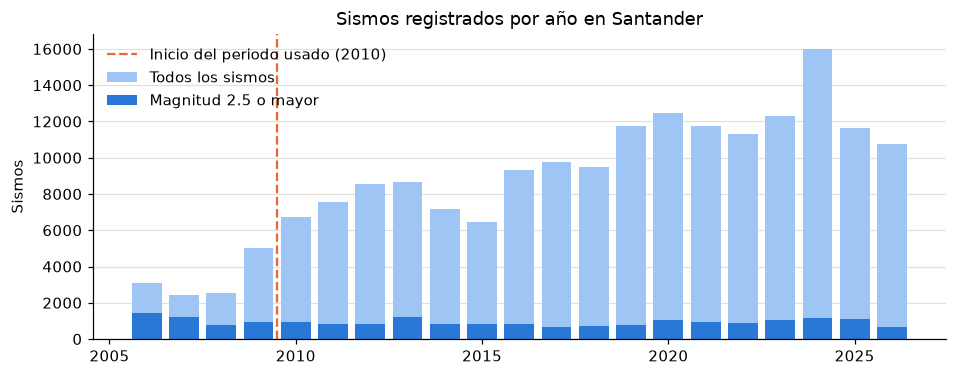

utc_time,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
todos,3069,2414,2552,5025,6731,7543,8542,8641,7153,6480,9329,9789,9479,11727,12442,11765,11286,12307,16016,11663,10770
M>=2.5,1426,1217,785,942,954,827,845,1235,807,809,852,677,739,792,1030,945,890,1029,1160,1132,667


In [9]:
por_anio = cat.groupby(cat["utc_time"].dt.year).size()
homogeneo_anio = cat[cat["magnitude"] >= clasificador.MAGNITUD_MINIMA].groupby(cat["utc_time"].dt.year).size()
fig, eje = plt.subplots(figsize=(10, 3.6))
eje.bar(por_anio.index, por_anio.values, color="#9ec5f4", label="Todos los sismos")
eje.bar(homogeneo_anio.index, homogeneo_anio.values, color=AZUL, label=f"Magnitud {clasificador.MAGNITUD_MINIMA} o mayor")
eje.axvline(clasificador.ANIO_INICIO - 0.5, color=NARANJA, linestyle="--", label=f"Inicio del periodo usado ({clasificador.ANIO_INICIO})")
eje.set(title="Sismos registrados por año en Santander", ylabel="Sismos"); eje.legend(frameon=False); eje.grid(axis="x", visible=False)
plt.show()
display(pd.DataFrame({"todos": por_anio, f"M>={clasificador.MAGNITUD_MINIMA}": homogeneo_anio}).T)

**El hallazgo más importante.** El total de sismos registrados crece año tras año, pero los de magnitud 2,5 o mayor apenas cambian (+10 % entre 2010-2017 y 2018-2025, frente a +51 % del total; véase la tabla de la sección 5).
El nido no se volvió más activo: la red sismológica mejoró y detecta cada vez más sismos pequeños. Un modelo que contara todos los sismos
aprendería la mejora de la red, no la sismicidad.

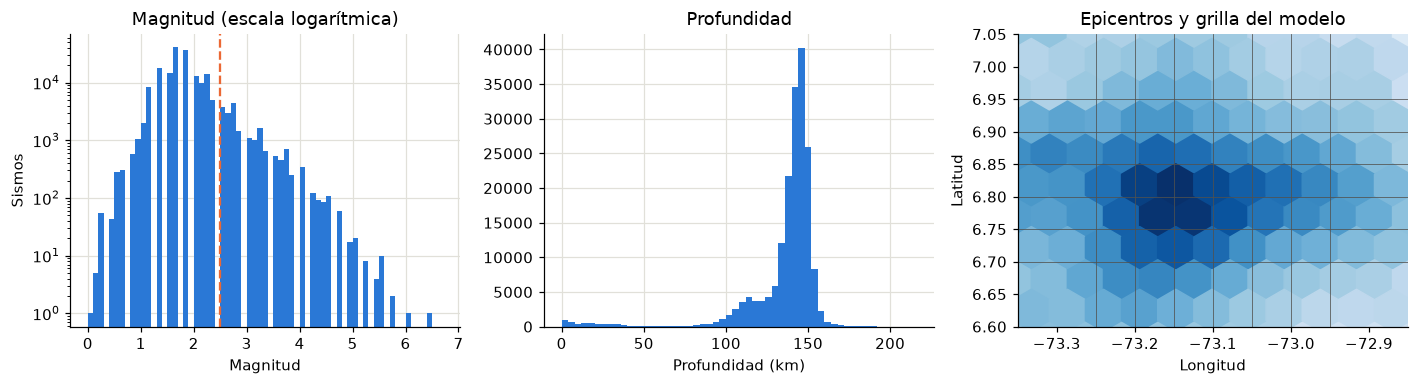

Magnitud: de -1.3 a 6.4, media 1.86
Profundidad: media 135.3 km, desviación 24.2 km


In [10]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6))
ejes[0].hist(cat["magnitude"], bins=np.arange(0, 6.8, 0.1), color=AZUL); ejes[0].set_yscale("log")
ejes[0].axvline(clasificador.MAGNITUD_MINIMA, color=NARANJA, linestyle="--")
ejes[0].set(title="Magnitud (escala logarítmica)", xlabel="Magnitud", ylabel="Sismos")
ejes[1].hist(cat["depth"], bins=np.arange(0, 220, 4), color=AZUL)
ejes[1].set(title="Profundidad", xlabel="Profundidad (km)")
hb = ejes[2].hexbin(cat["longitude"], cat["latitude"], gridsize=45, bins="log", cmap="Blues", mincnt=1)
for i in range(clasificador.N_COLUMNAS + 1):
    ejes[2].axvline(clasificador.LON_MIN + i * clasificador.GRID_STEP, color="#52514e", linewidth=0.5)
for i in range(clasificador.N_FILAS + 1):
    ejes[2].axhline(clasificador.LAT_MIN + i * clasificador.GRID_STEP, color="#52514e", linewidth=0.5)
ejes[2].set(title="Epicentros y grilla del modelo", xlabel="Longitud", ylabel="Latitud",
            xlim=(clasificador.LON_MIN - 0.1, clasificador.LON_MIN + clasificador.N_COLUMNAS * clasificador.GRID_STEP + 0.1),
            ylim=(clasificador.LAT_MIN - 0.1, clasificador.LAT_MIN + clasificador.N_FILAS * clasificador.GRID_STEP + 0.1))
ejes[2].grid(False); plt.tight_layout(); plt.show()
print(f"Magnitud: de {cat['magnitude'].min()} a {cat['magnitude'].max()}, media {cat['magnitude'].mean():.2f}")
print(f"Profundidad: media {cat['depth'].mean():.1f} km, desviación {cat['depth'].std():.1f} km")

## 5. Catálogo homogéneo

Para el modelo se usan solo los sismos de **magnitud 2,5 o mayor desde 2010**, que la red registra de forma estable,
y solo los que caen dentro de la grilla de Los Santos o en su margen (cinco celdas a cada lado, que sirven para calcular la actividad de las celdas vecinas).
El último trimestre, que está incompleto, se descarta.

In [11]:
anios = cat["utc_time"].dt.year
tabla = []
for nombre, filtro in [("Todos", cat["magnitude"] >= 0), ("Magnitud 2,0 o mayor", cat["magnitude"] >= 2.0),
                       ("Magnitud 2,5 o mayor", cat["magnitude"] >= 2.5), ("Magnitud 3,0 o mayor", cat["magnitude"] >= 3.0)]:
    antes = filtro[(anios >= 2010) & (anios <= 2017)].sum() / 8
    despues = filtro[(anios >= 2018) & (anios <= 2025)].sum() / 8
    tabla.append([nombre, round(antes), round(despues), f"{100 * (despues / antes - 1):+.0f} %"])
display(pd.DataFrame(tabla, columns=["Sismos por año (promedio)", "2010-2017", "2018-2025", "Cambio"]))

homogeneo = clasificador.preparar_catalogo(cat)
n_ventanas = int(homogeneo["ventana"].max()) + 1
embudo = [
    ("Catálogo limpio", len(cat)),
    (f"Desde {clasificador.ANIO_INICIO}", int((anios >= clasificador.ANIO_INICIO).sum())),
    (f"Y con magnitud {clasificador.MAGNITUD_MINIMA} o mayor", int(((anios >= clasificador.ANIO_INICIO) & (cat["magnitude"] >= clasificador.MAGNITUD_MINIMA)).sum())),
    ("Y dentro de la grilla ampliada (zona y margen), en trimestres completos", len(homogeneo)),
    ("De ellos, dentro de las 30 celdas de Los Santos", int(clasificador.en_la_zona(homogeneo).sum())),
]
display(pd.DataFrame(embudo, columns=["Filtro", "Sismos"]))

# Por qué hace falta el catálogo de todo Santander: municipio que el SGC asigna a los sismos que caen en la zona
en_zona = homogeneo[clasificador.en_la_zona(homogeneo)]
municipio = en_zona["place"].str.replace(" - Santander, Colombia", "").value_counts()
display(municipio.head(8).rename("sismos en las 30 celdas").to_frame())
print(f"Sismos de la zona que el SGC no asigna a Los Santos: {len(en_zona) - municipio['Los Santos']:,} de {len(en_zona):,} "
      f"({1 - municipio['Los Santos'] / len(en_zona):.1%}). Con el catálogo filtrado por municipio no se veían.")
print(f"Trimestres completos: {n_ventanas} ({clasificador.etiqueta_de_ventana(0)} a {clasificador.etiqueta_de_ventana(n_ventanas - 1)})")

,Sismos por año (promedio),2010-2017,2018-2025,Cambio
0,Todos,8026,12085,+51 %
1,"Magnitud 2,0 o mayor",2451,3766,+54 %
2,"Magnitud 2,5 o mayor",876,965,+10 %
3,"Magnitud 3,0 o mayor",377,295,-22 %


,Filtro,Sismos
0,Catálogo limpio,184723
1,Desde 2010,171663
2,Y con magnitud 2.5 o mayor,15390
3,Y dentro de la grilla ampliada (zona y margen)...,14292
4,"De ellos, dentro de las 30 celdas de Los Santos",13741


,sismos en las 30 celdas
place,
Los Santos,11964
Zapatoca,1407
Cepitá,135
Villanueva,130
Jordán Sube,22
Jordán,21
Betulia,18
Girón,17


Sismos de la zona que el SGC no asigna a Los Santos: 1,777 de 13,741 (12.9%). Con el catálogo filtrado por municipio no se veían.
Trimestres completos: 67 (2010-T1 a 2026-T3)


## 6. Conjunto de datos para el modelo

El reto pide clasificar **zonas**, no sismos. Cada fila es una **celda de 0,05° en un trimestre**, con 15 variables calculadas
con lo ocurrido hasta ese trimestre, y la etiqueta es lo que pasó en el **trimestre siguiente**.

In [12]:
grilla = clasificador.crear_grilla(homogeneo)
variables = clasificador.calcular_variables(homogeneo, grilla, n_ventanas)
dataset = clasificador.construir_dataset(variables, grilla, n_ventanas)

es_prueba = dataset["inicio_objetivo"] >= clasificador.FECHA_INICIO_PRUEBA
actividad = dataset[~es_prueba].groupby("cell_id")["sismos_trimestre"].sum()
celdas_activas = actividad[actividad > 0].index
print(f"Celdas en la grilla: {len(grilla)}   Con sismos en el periodo de entrenamiento: {len(celdas_activas)}")
print(f"Filas antes de quitar las celdas sin sismos en el entrenamiento: {len(dataset):,}")
dataset = dataset[dataset["cell_id"].isin(celdas_activas)].reset_index(drop=True)
es_prueba = dataset["inicio_objetivo"] >= clasificador.FECHA_INICIO_PRUEBA
print(f"Filas del conjunto de datos: {len(dataset):,}   Variables: {len(clasificador.FEATURES)}")

# La etiqueta: ningún sismo en el trimestre siguiente, de 1 a 3 (uno por mes en promedio) o más de 3
umbrales = clasificador.UMBRALES_SISMOS
dataset["nivel_riesgo"] = clasificador.clasificar(dataset["sismos_trimestre_siguiente"], umbrales)
print(f"Etiqueta: Bajo hasta {umbrales[0]:.0f} sismos · Medio hasta {umbrales[1]:.0f} · Alto más de {umbrales[1]:.0f}")
display(dataset.drop(columns=["ventana", "inicio_objetivo"]).head(8))

Celdas en la grilla: 30   Con sismos en el periodo de entrenamiento: 30
Filas antes de quitar las celdas sin sismos en el entrenamiento: 1,890
Filas del conjunto de datos: 1,890   Variables: 15
Etiqueta: Bajo hasta 0 sismos · Medio hasta 3 · Alto más de 3


,cell_id,sismos_trimestre,sismos_ultimo_anio,sismos_promedio_historico,tendencia_sismos,sismos_vecinos_ultimo_anio,mag_media_ultimo_anio,mag_max_ultimo_anio,log_energia_ultimo_anio,prop_moderados_ultimo_anio,trimestres_desde_sismo_fuerte,prof_media_ultimo_anio,prof_std_ultimo_anio,dist_nido_km,lat_center,lon_center,trimestre,trimestre_objetivo,sismos_trimestre_siguiente,nivel_riesgo
0,0,0.000,0.000,0.000,0.000,31.000,0.000,0.000,0.000,0.000,67.000,0.000,0.000,11.980,6.725,-73.225,2010-T4,2011-T1,0.000,Bajo
1,1,4.000,5.000,1.250,2.750,188.000,2.740,3.400,9.994,0.000,67.000,142.600,2.417,9.024,6.725,-73.175,2010-T4,2011-T1,2.000,Medio
2,2,5.000,5.000,1.250,3.750,430.000,2.580,2.700,9.384,0.000,67.000,142.200,3.709,8.957,6.725,-73.125,2010-T4,2011-T1,2.000,Medio
3,3,0.000,1.000,0.250,-0.250,498.000,2.800,2.800,9.000,0.000,67.000,144.000,0.000,11.827,6.725,-73.075,2010-T4,2011-T1,1.000,Medio
4,4,0.000,2.000,0.500,-0.500,364.000,2.800,2.900,9.326,0.000,67.000,143.500,3.500,16.137,6.725,-73.025,2010-T4,2011-T1,0.000,Bajo
5,5,0.000,4.000,1.000,-1.000,125.000,2.850,3.400,10.027,0.000,67.000,148.000,1.225,21.019,6.725,-72.975,2010-T4,2011-T1,0.000,Bajo
6,6,0.000,1.000,0.250,-0.250,49.000,2.900,2.900,9.150,0.000,67.000,141.000,0.000,8.906,6.775,-73.225,2010-T4,2011-T1,2.000,Medio
7,7,18.000,24.000,6.000,12.000,263.000,2.925,4.300,11.419,0.167,3.000,142.958,4.860,4.151,6.775,-73.175,2010-T4,2011-T1,38.000,Alto


In [13]:
print("Valores faltantes en el conjunto de datos:", int(dataset[clasificador.FEATURES + ["nivel_riesgo"]].isna().sum().sum()))
print("Filas repetidas (misma celda y trimestre):", int(dataset.duplicated(["cell_id", "trimestre"]).sum()))
display(dataset[clasificador.FEATURES].describe().T[["count", "mean", "std", "min", "50%", "max"]])

Valores faltantes en el conjunto de datos: 0
Filas repetidas (misma celda y trimestre): 0


,count,mean,std,min,50%,max
sismos_trimestre,"1,890.000",6.838,19.012,0.000,0.000,141.000
sismos_ultimo_anio,"1,890.000",27.401,72.551,0.000,1.000,435.000
sismos_promedio_historico,"1,890.000",6.627,14.279,0.000,0.483,64.659
tendencia_sismos,"1,890.000",-0.012,5.896,-49.000,0.000,52.500
sismos_vecinos_ultimo_anio,"1,890.000",212.890,240.553,0.000,95.000,914.000
mag_media_ultimo_anio,"1,890.000",1.545,1.478,0.000,2.500,5.000
mag_max_ultimo_anio,"1,890.000",1.965,1.964,0.000,2.500,6.400
log_energia_ultimo_anio,"1,890.000",5.640,5.418,0.000,8.550,14.400
prop_moderados_ultimo_anio,"1,890.000",0.077,0.184,0.000,0.000,1.000
trimestres_desde_sismo_fuerte,"1,890.000",39.925,29.337,0.000,67.000,67.000


,Entrenamiento,Prueba
nivel_riesgo,,
Bajo,878,350
Medio,186,86
Alto,256,134
Total,1320,570


Entrenamiento: 2011-T1 a 2021-T4
Prueba:        2022-T1 a 2026-T3  (el modelo nunca lo ve al entrenar)


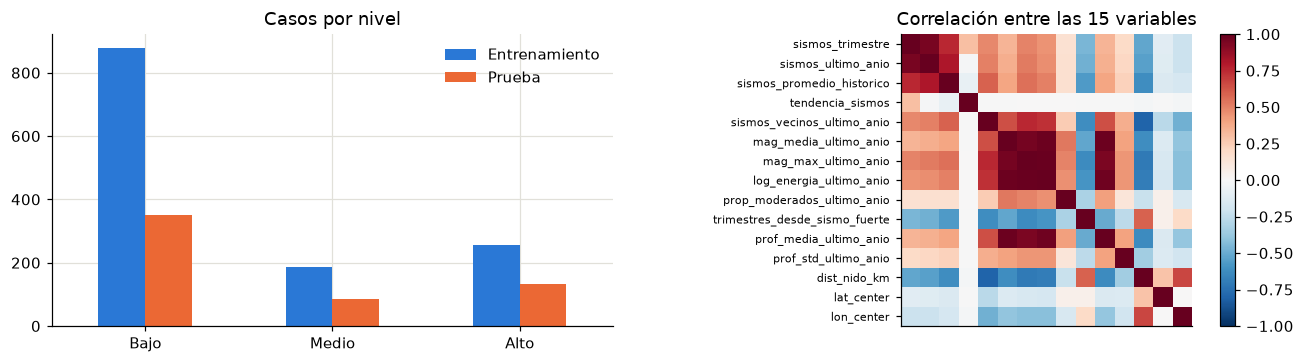

In [14]:
train, test = dataset[~es_prueba], dataset[es_prueba]
reparto = pd.DataFrame({
    "Entrenamiento": train["nivel_riesgo"].value_counts(), "Prueba": test["nivel_riesgo"].value_counts(),
}).reindex(clasificador.NIVELES)
reparto.loc["Total"] = reparto.sum()
display(reparto)
print(f"Entrenamiento: {train['trimestre_objetivo'].iloc[0]} a {train['trimestre_objetivo'].iloc[-1]}")
print(f"Prueba:        {test['trimestre_objetivo'].iloc[0]} a {test['trimestre_objetivo'].iloc[-1]}  (el modelo nunca lo ve al entrenar)")

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.4))
reparto.drop("Total").plot.bar(ax=ejes[0], color=[AZUL, NARANJA], rot=0); ejes[0].set(title="Casos por nivel", xlabel=""); ejes[0].legend(frameon=False)
correlacion = dataset[clasificador.FEATURES].corr()
imagen = ejes[1].imshow(correlacion, cmap="RdBu_r", vmin=-1, vmax=1); ejes[1].grid(False)
ejes[1].set_xticks([]); ejes[1].set_yticks(range(len(clasificador.FEATURES))); ejes[1].set_yticklabels(clasificador.FEATURES, fontsize=7)
ejes[1].set_title("Correlación entre las 15 variables"); fig.colorbar(imagen, ax=ejes[1], fraction=0.046)
plt.tight_layout(); plt.show()

## 7. ¿Están normalizados los datos?

Depende de a qué se llame «normalizado»; aquí se responden los dos sentidos.

**Estructura (datos ordenados).** Sí: el catálogo limpio tiene una fila por sismo y una columna por dato, con un solo tipo por columna;
el conjunto de datos tiene una fila por celda y trimestre, sin repetidos ni faltantes.

**Escala de las variables.** Los archivos guardados (`catalogo_limpio_los_santos.csv` y `dataset_entrenamiento_los_santos.csv`)
están **en sus unidades reales**, sin escalar, a propósito: así se pueden leer y revisar. El escalado se hace **dentro del modelo**, solo donde hace falta:

In [15]:
from sklearn.preprocessing import StandardScaler

X_train = train[clasificador.FEATURES]
escalador = StandardScaler().fit(X_train)                      # se ajusta SOLO con el entrenamiento
escalado = pd.DataFrame(escalador.transform(X_train), columns=clasificador.FEATURES)
display(pd.DataFrame({
    "mínimo (original)": X_train.min(), "máximo (original)": X_train.max(),
    "media (original)": X_train.mean(), "desviación (original)": X_train.std(),
    "media (escalada)": escalado.mean().values, "desviación (escalada)": escalado.std(ddof=0).values,
}))
for nombre, modelo in clasificador.crear_modelos().items():
    pasos_del_modelo = [type(p).__name__ for _, p in modelo.steps] if hasattr(modelo, "steps") else [type(modelo).__name__]
    print(f"{nombre:22s} -> {' + '.join(pasos_del_modelo)}")

,mínimo (original),máximo (original),media (original),desviación (original),media (escalada),desviación (escalada)
sismos_trimestre,0.000,141.000,6.471,18.407,-0.000,1.000
sismos_ultimo_anio,0.000,422.000,25.928,70.423,-0.000,1.000
sismos_promedio_historico,0.000,64.659,6.613,14.385,0.000,1.000
tendencia_sismos,-49.000,52.500,-0.011,6.106,0.000,1.000
sismos_vecinos_ultimo_anio,0.000,914.000,205.182,228.534,-0.000,1.000
mag_media_ultimo_anio,0.000,5.000,1.532,1.507,-0.000,1.000
mag_max_ultimo_anio,0.000,6.400,1.936,1.978,-0.000,1.000
log_energia_ultimo_anio,0.000,14.400,5.525,5.442,-0.000,1.000
prop_moderados_ultimo_anio,0.000,1.000,0.090,0.202,0.000,1.000
trimestres_desde_sismo_fuerte,0.000,67.000,40.820,30.050,-0.000,1.000


Regresión Logística    -> StandardScaler + LogisticRegression
Random Forest          -> RandomForestClassifier


- **Regresión Logística:** lleva un `StandardScaler` dentro de su *pipeline*. Cada variable se lleva a media 0 y desviación 1,
  con la media y la desviación **del periodo de entrenamiento únicamente**, para no filtrar información de la prueba.
- **Random Forest (el modelo elegido):** no se escala, porque no lo necesita. Un árbol solo pregunta si una variable supera un umbral,
  y eso no cambia al escalarla. Escalar no mejoraría ni empeoraría su resultado.

## 8. Entrenamiento y resultados del clasificador

El Random Forest tiene dos ajustes que no se fijan a mano: el **balanceo** (cuánto se compensa que haya pocos casos de nivel Medio y Alto; con 1 las tres clases pesan igual y con 0 no se compensa nada) y la **profundidad** de los árboles. Se eligen con validación hacia adelante dentro del periodo de entrenamiento: para cada año de 2017 a 2021 se entrena con los años anteriores y se predice ese año. El periodo de prueba no interviene en la elección.

In [16]:
y_train, X_test, y_test = train["nivel_riesgo"], test[clasificador.FEATURES], test["nivel_riesgo"]
predicciones = {
    "Regla: clase más frecuente": np.full(len(test), y_train.value_counts().idxmax()),
    "Regla: igual al trimestre anterior": clasificador.clasificar(test["sismos_trimestre"], umbrales),
    "Regla: promedio del último año": clasificador.clasificar(test["sismos_ultimo_anio"] / clasificador.VENTANAS_POR_ANIO, umbrales),
}
# Ajustes del Random Forest: se eligen con validación dentro del entrenamiento, sin mirar la prueba
balanceo, profundidad, validacion = clasificador.elegir_ajustes(train)
print(f"Ajustes elegidos: balanceo {balanceo}, profundidad {profundidad}")
display((validacion.head(6).assign(**{c: (100 * validacion[c]).round(2) for c in ('accuracy', 'f1_macro', 'recall_alto')})))
modelos = clasificador.crear_modelos(y_train, balanceo, profundidad)
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    predicciones[nombre] = modelo.predict(X_test)
metricas = {nombre: clasificador.evaluar(y_test, p) for nombre, p in predicciones.items()}
techo = clasificador.evaluar(y_test, clasificador.techo_del_problema(variables["sismos_trimestre"], test, umbrales))
elegido = max(modelos, key=lambda nombre: metricas[nombre]["f1_macro"])

resultados = pd.DataFrame(metricas).T
resultados.loc["Techo de referencia (oráculo)"] = techo
display((100 * resultados).round(2).rename(columns={"accuracy": "Exactitud %", "f1_macro": "F1 macro %", "recall_alto": "Recall del nivel Alto %"}))
print("Modelo elegido (mejor F1 macro):", elegido)
print(f"Alcanza el {metricas[elegido]['accuracy'] / techo['accuracy']:.0%} de la exactitud del techo de referencia")

Ajustes elegidos: balanceo 0.75, profundidad 6


,balanceo,profundidad,accuracy,f1_macro,recall_alto
0,0.750,6,80.830,69.450,79.050
1,0.750,10,80.500,69.080,79.620
2,1.000,10,78.670,68.840,79.620
3,0.500,6,82.170,68.760,79.050
4,1.000,6,77.830,68.560,77.790
5,0.500,10,82.000,68.330,79.460


,Exactitud %,F1 macro %,Recall del nivel Alto %
Regla: clase más frecuente,61.400,25.360,0.000
Regla: igual al trimestre anterior,80.180,70.850,86.570
Regla: promedio del último año,70.880,66.480,93.280
Regresión Logística,76.320,70.550,81.340
Random Forest,80.700,71.920,84.330
Techo de referencia (oráculo),82.810,72.250,91.790


Modelo elegido (mejor F1 macro): Random Forest
Alcanza el 97% de la exactitud del techo de referencia


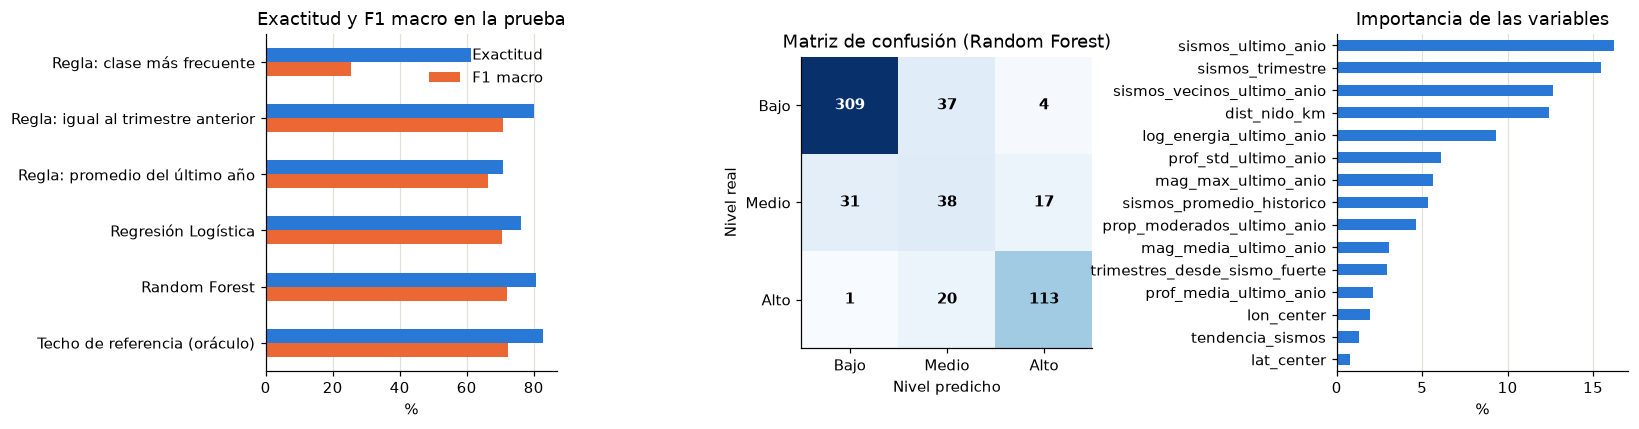

              precision    recall  f1-score   support

        Bajo     0.9062    0.8829    0.8944       350
       Medio     0.4000    0.4419    0.4199        86
        Alto     0.8433    0.8433    0.8433       134

    accuracy                         0.8070       570
   macro avg     0.7165    0.7227    0.7192       570
weighted avg     0.8150    0.8070    0.8108       570



In [17]:
from sklearn.metrics import classification_report, confusion_matrix

matriz = confusion_matrix(y_test, predicciones[elegido], labels=clasificador.NIVELES)
importancias = pd.Series(modelos["Random Forest"].feature_importances_, index=clasificador.FEATURES).sort_values()
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
(100 * resultados[["accuracy", "f1_macro"]]).plot.barh(ax=ejes[0], color=[AZUL, NARANJA]); ejes[0].invert_yaxis()
ejes[0].set(title="Exactitud y F1 macro en la prueba", xlabel="%"); ejes[0].legend(["Exactitud", "F1 macro"], frameon=False); ejes[0].grid(axis="y", visible=False)
ejes[1].imshow(matriz, cmap="Blues"); ejes[1].grid(False)
ejes[1].set(title=f"Matriz de confusión ({elegido})", xlabel="Nivel predicho", ylabel="Nivel real",
            xticks=range(3), yticks=range(3), xticklabels=clasificador.NIVELES, yticklabels=clasificador.NIVELES)
for i in range(3):
    for j in range(3):
        ejes[1].text(j, i, matriz[i, j], ha="center", va="center", color="white" if matriz[i, j] > matriz.max() / 2 else "black", fontweight="bold")
(100 * importancias).plot.barh(ax=ejes[2], color=AZUL); ejes[2].set(title="Importancia de las variables", xlabel="%"); ejes[2].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(classification_report(y_test, predicciones[elegido], labels=clasificador.NIVELES, digits=4, zero_division=0))

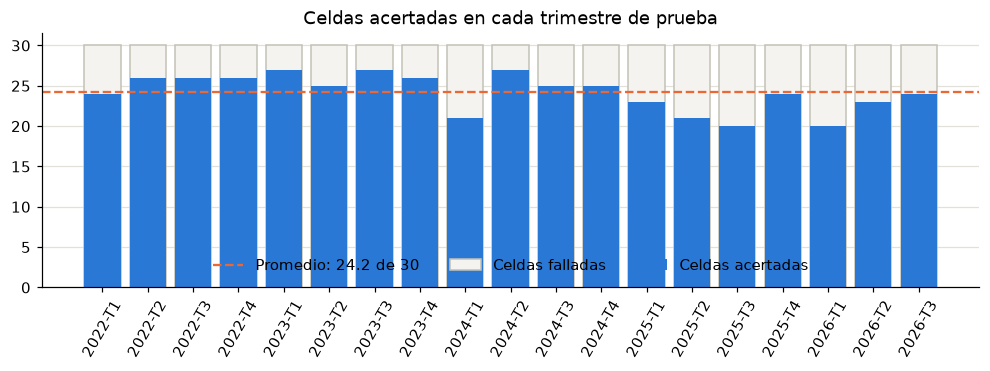

In [18]:
# Aciertos por trimestre del periodo de prueba
aciertos = (test.assign(acierto=predicciones[elegido] == y_test.to_numpy()).groupby("trimestre_objetivo")["acierto"].agg(["sum", "count"]))
fig, eje = plt.subplots(figsize=(11, 3))
eje.bar(aciertos.index, aciertos["count"], color="#f4f3ef", edgecolor=GRIS, label="Celdas falladas")
eje.bar(aciertos.index, aciertos["sum"], color=AZUL, label="Celdas acertadas")
eje.axhline(aciertos["sum"].mean(), color=NARANJA, linestyle="--", label=f"Promedio: {aciertos['sum'].mean():.1f} de {aciertos['count'].iloc[0]}")
eje.set(title="Celdas acertadas en cada trimestre de prueba"); eje.tick_params(axis="x", rotation=60); eje.grid(axis="x", visible=False)
eje.legend(frameon=False, ncol=3, loc="lower center"); plt.show()

In [19]:
# Comprobación: lo calculado aquí debe coincidir con lo que guardó el script de entrenamiento
guardado = json.loads(clasificador.METRICAS_JSON.read_text(encoding="utf-8"))
assert guardado["modelo_elegido"] == elegido
assert guardado["matriz_confusion"]["valores"] == matriz.tolist()
for nombre, m in metricas.items():
    for clave, valor in m.items():
        assert abs(guardado["metricas"][nombre.replace("Regla:", "Base:")][clave] - valor) < 1e-9, (nombre, clave)
print("Comprobado: métricas y matriz de confusión idénticas a las de 1_sismos_los_santos/models/metricas_clasificador.json")
print(f"Exactitud {metricas[elegido]['accuracy']:.2%} · F1 macro {metricas[elegido]['f1_macro']:.2%} · Recall del nivel Alto {metricas[elegido]['recall_alto']:.2%}")

Comprobado: métricas y matriz de confusión idénticas a las de 1_sismos_los_santos/models/metricas_clasificador.json
Exactitud 80.70% · F1 macro 71.92% · Recall del nivel Alto 84.33%


## 9. Datos del simulador de sacudida

El simulador no se entrena con el catálogo del SGC: usa una relación física publicada (Zhao et al., 2006; Worden et al., 2012)
y se calibra con las intensidades que la población reportó al USGS.

Archivo original: data/raw/intensidades_dyfi_usgs.csv  ·  598 observaciones de 86 sismos
Valores faltantes: 0  · Filas repetidas: 0


,evento_id,fecha_utc,magnitud,tipo_magnitud,ev_lat,ev_lon,ev_prof_km,obs_lat,obs_lon,intensidad_cdi,n_respuestas
0,us7000tbzn,2026-08-26T16:45:14.482000+00:00,4.900,mww,6.755,-73.004,158.980,7.083,-73.129,3.100,4
1,us7000tbzn,2026-08-26T16:45:14.482000+00:00,4.900,mww,6.755,-73.004,158.980,6.450,-73.131,2.900,1
2,us7000tbzn,2026-08-26T16:45:14.482000+00:00,4.900,mww,6.755,-73.004,158.980,6.811,-73.040,2.700,1
3,us7000tbzn,2026-08-26T16:45:14.482000+00:00,4.900,mww,6.755,-73.004,158.980,6.182,-75.392,2.400,2
4,us7000tbzn,2026-08-26T16:45:14.482000+00:00,4.900,mww,6.755,-73.004,158.980,5.006,-75.481,2.200,1


,count,mean,std,min,25%,50%,75%,max
magnitud,598.000,5.204,0.472,4.500,4.900,5.100,5.400,6.200
ev_prof_km,598.000,158.190,5.553,135.340,155.000,158.846,160.432,177.195
intensidad_cdi,598.000,2.931,0.906,1.000,2.200,2.800,3.400,6.400
n_respuestas,598.000,3.062,7.344,1.000,1.000,1.000,2.000,100.000


,descripcion,rmse,mae,sesgo,dentro_de_1_grado
fisico,Cálculo físico sin ajustar (Zhao 2006 + Worden...,1.037,0.789,-0.427,0.681
fisico_sesgo,Físico + corrección constante del sesgo,0.964,0.762,0.076,0.732
fisico_lineal,Físico + regresión lineal del residuo,0.800,0.615,0.080,0.823
fisico_rf,Físico + Random Forest del residuo,0.853,0.667,0.010,0.774
fisico_rf_espacial,Físico + Random Forest del residuo con ubicación,0.835,0.651,0.004,0.783
lineal_puro,Regresión lineal sin física (referencia),0.808,0.629,0.075,0.819
rf_puro,Random Forest sin física (referencia),0.870,0.679,-0.035,0.759


Validación: dejando fuera un sismo completo cada vez · Modelo elegido: fisico_lineal
Rango validado: [4.5, 6.2] de magnitud y [135, 177] km de profundidad


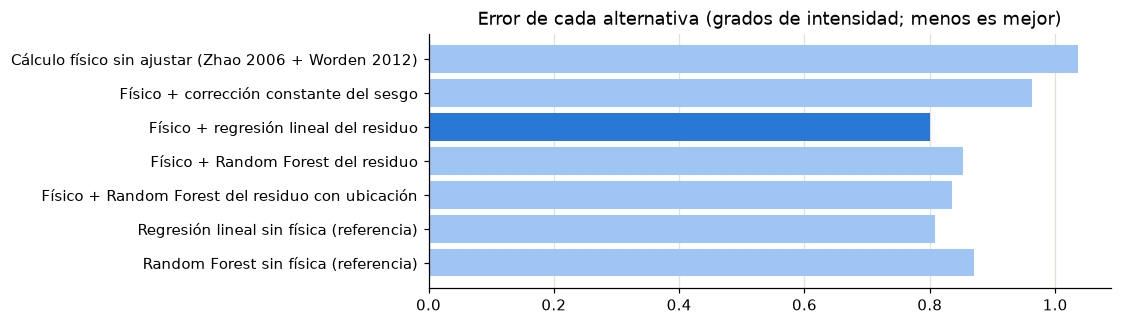

In [20]:
crudo_usgs = pd.read_csv(sacudida.INTENSIDADES_CSV)
print(f"Archivo original: {relativa(sacudida.INTENSIDADES_CSV)}  ·  {len(crudo_usgs)} observaciones de {crudo_usgs['evento_id'].nunique()} sismos")
print("Valores faltantes:", int(crudo_usgs.isna().sum().sum()), " · Filas repetidas:", int(crudo_usgs.duplicated().sum()))
display(crudo_usgs.head(5))
display(crudo_usgs[["magnitud", "ev_prof_km", "intensidad_cdi", "n_respuestas"]].describe().T)

validacion = json.loads(sacudida.METRICAS_JSON.read_text(encoding="utf-8"))
candidatos = pd.DataFrame(validacion["candidatos"]).T[["descripcion", "rmse", "mae", "sesgo", "dentro_de_1_grado"]]
display(candidatos)
print("Validación:", validacion["validacion"], "· Modelo elegido:", validacion["modelo_elegido"])
print("Rango validado:", validacion["rango_validado"]["magnitud"], "de magnitud y", [round(v) for v in validacion["rango_validado"]["prof_km"]], "km de profundidad")
fig, eje = plt.subplots(figsize=(8, 3))
eje.barh(candidatos["descripcion"], candidatos["rmse"].astype(float), color=[AZUL if i == validacion["modelo_elegido"] else "#9ec5f4" for i in candidatos.index])
eje.invert_yaxis(); eje.set(title="Error de cada alternativa (grados de intensidad; menos es mejor)"); eje.grid(axis="y", visible=False); plt.show()

## 10. Población del DANE

Se usa para contar las personas expuestas en el simulador. Aquí se ve el archivo original y cómo queda limpio.

In [21]:
original = pd.read_excel(poblacion.ARCHIVO_XLSX, sheet_name=poblacion.HOJA, header=poblacion.FILA_DE_ENCABEZADOS, dtype=str)
print(f"Archivo original: {relativa(poblacion.ARCHIVO_XLSX)}  ·  {len(original):,} filas (todos los municipios del país, todos los años y áreas)")
display(original.head(4))
limpia = pd.read_csv(poblacion.SALIDA_CSV)
print(f"Archivo limpio: {relativa(poblacion.SALIDA_CSV)}  ·  {len(limpia)} municipios de Santander, año {limpia['anio'].iloc[0]}")
print(f"Población total: {limpia['poblacion_total'].sum():,}  ·  La cabecera más el área rural da el total en todos:",
      bool((limpia["poblacion_cabecera"] + limpia["poblacion_rural"] == limpia["poblacion_total"]).all()))
display(limpia.head(5))

Archivo original: data/raw/poblacion_dane/PPED-AreaMun-2018-2042_VP.xlsx  ·  84,234 filas (todos los municipios del país, todos los años y áreas)


,DP,DPNOM,MPIO,DPMP,AÑO,ÁREA GEOGRÁFICA,TOTAL
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,05,Antioquia,05001,Medellín,2018,Cabecera Municipal,2382405
2,05,Antioquia,05001,Medellín,2018,Centros Poblados y Rural Disperso,44728
3,05,Antioquia,05001,Medellín,2018,Total,2427133


Archivo limpio: comun/data/processed/poblacion_santander.csv  ·  87 municipios de Santander, año 2026
Población total: 2,410,700  ·  La cabecera más el área rural da el total en todos: True


,anio,municipio,codigo_dane,municipio_dane,poblacion_cabecera,poblacion_rural,poblacion_total
0,2026,Aguada,68013,Aguada,410,1502,1912
1,2026,Albania,68020,Albania,770,3475,4245
2,2026,Aratoca,68051,Aratoca,2916,5928,8844
3,2026,Barbosa,68077,Barbosa,26273,7969,34242
4,2026,Barichara,68079,Barichara,4345,8811,13156


## 11. Qué queda guardado

Originales en `entrenamiento/data/raw` (sin modificar). Lo que comparten varios modelos queda en `comun/` (catálogo limpio, población, modelo de sacudida) y lo propio de este modelo en `1_sismos_los_santos/`.

In [22]:
for carpeta in (catalogo.PROCESSED_DIR, catalogo.MODELS_DIR, clasificador.PROCESSED_DIR, clasificador.MODELS_DIR):
    print(relativa(carpeta) + "/")
    for ruta in sorted(carpeta.glob("*")):
        if ruta.is_file():
            print(f"   {ruta.name:45s} {ruta.stat().st_size / 1e3:10.0f} KB")

comun/data/processed/
   catalogo_limpio_santander.csv                      34379 KB
   grilla_santander.geojson                             755 KB
   poblacion_santander.csv                                4 KB
comun/models/
   metricas_validacion.json                               4 KB
   modelo_sacudida_santander.pkl                          2 KB
1_sismos_los_santos/data/processed/
   dataset_entrenamiento_los_santos.csv                 305 KB
   grilla_riesgo_los_santos.geojson                      26 KB
1_sismos_los_santos/models/
   historial_prueba.json                                  5 KB
   metricas_clasificador.json                             4 KB
   modelo_riesgo_sismico_los_santos.pkl                2351 KB


**Resumen.**

1. El catálogo del SGC de todo Santander llega con 184.723 sismos, todos sus datos como texto; tras la limpieza conserva todos los que tienen magnitud, ubicación y fecha.
2. Para el modelo se usan los sismos de magnitud 2,5 o mayor desde 2010, que la red registra de forma estable, en la zona de Los Santos y su margen. Uno de cada ocho sismos de la zona está asignado a un municipio vecino: por eso se entrena con el catálogo departamental.
3. El conjunto de datos tiene una fila por celda y trimestre, 15 variables, sin faltantes ni repetidos.
4. Los archivos se guardan en unidades reales; el escalado ocurre dentro del modelo que lo necesita (Regresión Logística) y se ajusta solo con el entrenamiento.
5. El Random Forest elegido se evalúa con casi cinco años que no vio al entrenar, y sus resultados coinciden con los guardados.